Fashion-MNIST is a dataset of Zalando's article images—consisting of a training set of 60,000 examples and a test set of 10,000 examples. Each example is a 28x28 grayscale image, associated with a label from 10 classes.

In this assginment, we try to build a classifier for the Fashion-MNIST dataset that achieves over 94% accuracy on the test set. 

To achieve this goal, we
- use convnet for this purpose
- learn how to use padding in convnet
- learn how to use Batch Normalization and Dropout when training deep neural networks
- learn how to use nadam optimizer
- add more layers to the exisiting network model in function build_model()
- use validation data and observe the training history to determine whether the model is good enough to run test data
- use test data set only once.

This assignment is graded on the test accuracy. Any accuracy below 93% is graded as 0; any accuracy above 94% is graded as 100. Any grade in between is graded using the fomula  (acc - 0.93)/(0.94 - 0.93), 1))*100.

In [1]:
import numpy as np
import os

# to make this notebook's output stable across runs
np.random.seed(42)

# To plot pretty figures
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

In [2]:
import tensorflow as tf
fashion_mnist = tf.keras.datasets.fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

In [3]:
X_train.shape

(60000, 28, 28)

In [4]:
y_train.shape

(60000,)

In [5]:
y_test.shape

(10000,)

### Labels
Each training and test example is assigned to one of the following labels:

Label	Description
- 0	T-shirt/top
- 1	Trouser
- 2	Pullover
- 3	Dress
- 4	Coat
- 5	Sandal
- 6	Shirt
- 7	Sneaker
- 8	Bag
- 9	Ankle boot

In [6]:
def plot_digit(data):
    image = data.reshape(28, 28)
    plt.imshow(image, cmap = matplotlib.cm.binary, interpolation="nearest")
    plt.axis("off")

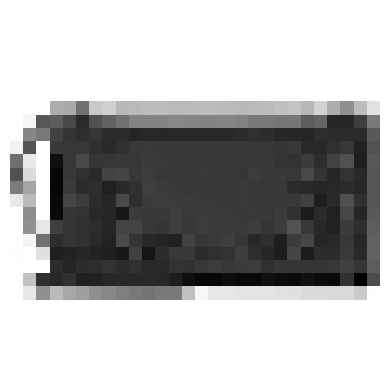

In [7]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt

some_digit = X_train[36001]
some_digit_image = some_digit.reshape(28, 28)
plt.imshow(some_digit_image, cmap = matplotlib.cm.binary, interpolation="nearest")
plt.axis("off");
plt.show()

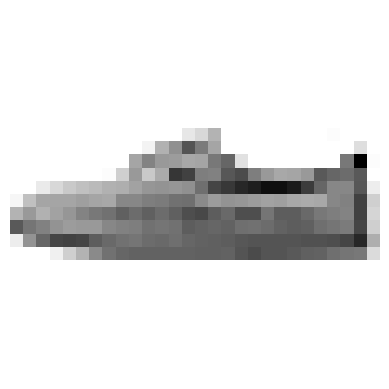

In [8]:
plot_digit(X_train[40000]);
plt.show()


In [9]:
def plot_digits(instances, images_per_row=10, **options):
    size = 28
    images_per_row = min(len(instances), images_per_row)
    images = [instance.reshape(size,size) for instance in instances]
    n_rows = (len(instances) - 1) // images_per_row + 1
    row_images = []
    n_empty = n_rows * images_per_row - len(instances)
    images.append(np.zeros((size, size * n_empty)))
    for row in range(n_rows):
        rimages = images[row * images_per_row : (row + 1) * images_per_row]
        row_images.append(np.concatenate(rimages, axis=1))
    image = np.concatenate(row_images, axis=0)
    plt.imshow(image, cmap = matplotlib.cm.binary, **options)
    plt.axis("off")

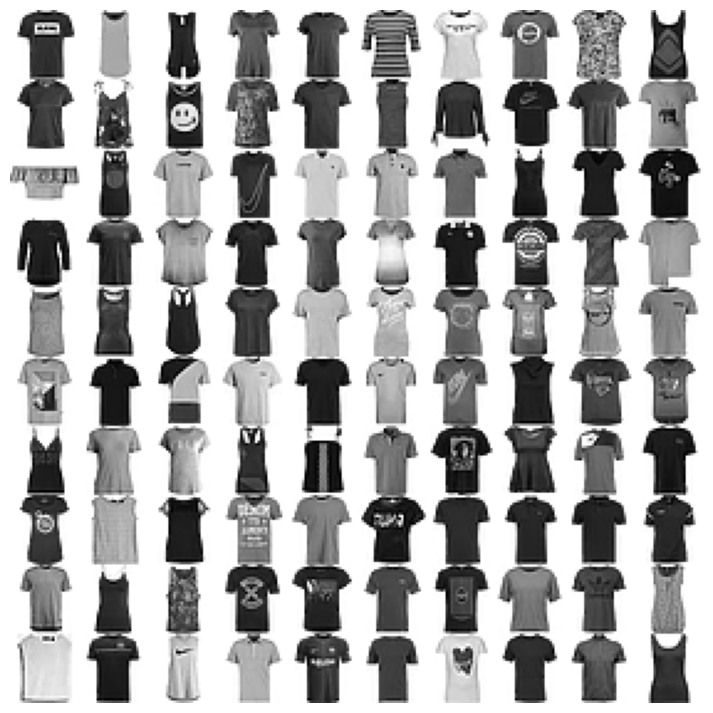

In [10]:
plt.figure(figsize=(9,9))
X_0 = X_train[(y_train == 0)]
example_images = X_0[:100]
plot_digits(example_images, images_per_row=10);
plt.show()

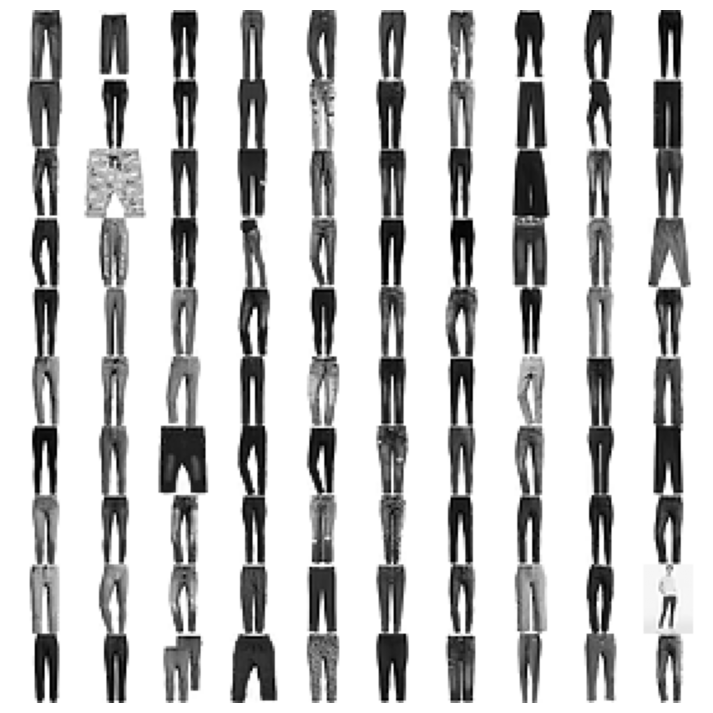

In [11]:
plt.figure(figsize=(9,9))
X_1 = X_train[(y_train == 1)]
example_images = X_1[:100]
plot_digits(example_images, images_per_row=10);
plt.show()

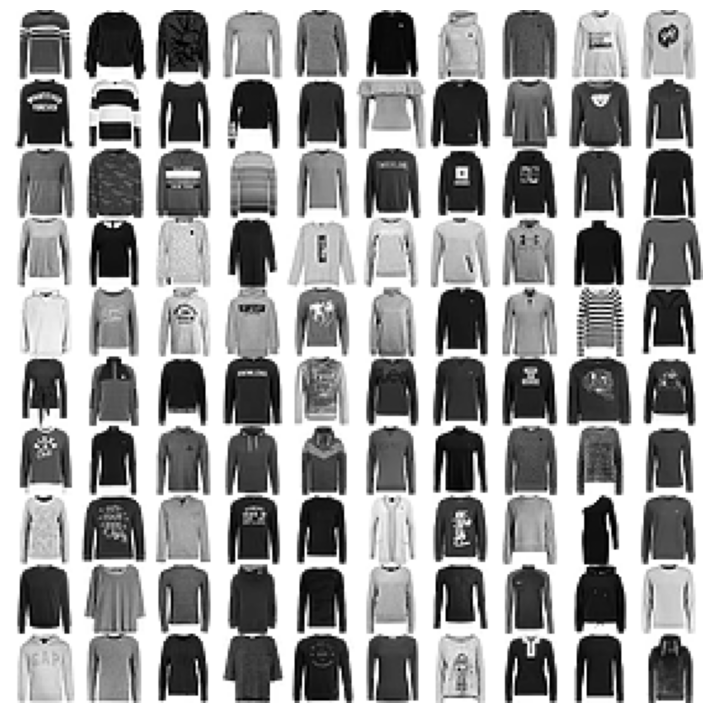

In [12]:
plt.figure(figsize=(9,9))
X_2 = X_train[(y_train == 2)]
example_images = X_2[:100]
plot_digits(example_images, images_per_row=10);
plt.show()

In [13]:
from keras import layers
from keras import models

def build_model():

    # we build a Y-network model with two inputs and one output

    input_shape=(28, 28, 1)
    
    # left branch
    left_inputs = layers.Input(shape=input_shape)
    x = layers.Conv2D(32, (3, 3), padding="same", activation='relu')(left_inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(32, (3, 3), padding="same", activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)

    # fill in code below to finsh the left branch
    x = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)

    # right branch
    right_inputs = layers.Input(shape=input_shape)
    y = layers.Conv2D(32, (3, 3), padding="same", activation='relu')(right_inputs)
    y = layers.BatchNormalization()(y)
    y = layers.Conv2D(32, (3, 3), padding="same", activation='relu')(y)
    y = layers.BatchNormalization()(y)
    y = layers.MaxPooling2D((2, 2))(y)
    y = layers.Dropout(0.25)(y)

    # fill in code below to finish the right branch
    y = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(y)
    y = layers.BatchNormalization()(y)
    y = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(y)
    y = layers.BatchNormalization()(y)
    y = layers.MaxPooling2D((2, 2))(y)
    y = layers.Dropout(0.25)(y)

    # concatenate the left and the right branches
    x = layers.concatenate([x, y])
    x = layers.Flatten()(x)

    x = layers.Dense(512, activation='relu')(x)
    x = layers.BatchNormalization()(x)

    # fill in code below
    x = layers.Dropout(0.5)(x)

    # outputs
    outputs = layers.Dense(10, activation='softmax')(x)
    model = models.Model([left_inputs, right_inputs], outputs=outputs)
    return model
model = build_model()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 28, 28,    │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 28, 28,    │        320 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 28, 28,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        128 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 28, 28,    │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 28, 28,    │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        128 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 14, 14,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 14, 14,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 14, 14,    │          0 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 14, 14,    │          0 │ max_pooling2d_2[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 14, 14,    │     18,496 │ dropout[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 14, 14,    │     18,496 │ dropout_2[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 14, 14,    │        256 │ conv2d_2[0][0]  

 Total params: 3,350,474 (12.78 MB)

 Trainable params: 3,348,682 (12.77 MB)

 Non-trainable params: 1,792 (7.00 KB)

In [14]:
from tensorflow.keras.utils import to_categorical

X_train = X_train.reshape((60000, 28, 28, 1))
X_train = X_train.astype('float32') / 255
y_train = to_categorical(y_train)

X_test = X_test.reshape((10000, 28, 28, 1))
X_test = X_test.astype('float32') / 255
y_test = to_categorical(y_test)

X_val = X_train[:10000]
y_val = y_train[:10000]

X_train_partial = X_train[10000:]
y_train_partial = y_train[10000:]

In [15]:
X_train_partial.shape, y_train_partial.shape, X_test.shape, y_test.shape

((50000, 28, 28, 1), (50000, 10), (10000, 28, 28, 1), (10000, 10))

In [16]:
model.compile(optimizer='nadam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])
history = model.fit([X_train_partial, X_train_partial], y_train_partial, epochs=40, batch_size=64, validation_data=([X_val, X_val], y_val))

Epoch 1/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 64s 74ms/step - accuracy: 0.8449 - loss: 0.4518 - val_accuracy: 0.9023 - val_loss: 0.2668
Epoch 2/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 62s 79ms/step - accuracy: 0.8968 - loss: 0.2882 - val_accuracy: 0.9111 - val_loss: 0.2382
Epoch 3/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 65s 83ms/step - accuracy: 0.9088 - loss: 0.2543 - val_accuracy: 0.9166 - val_loss: 0.2348
Epoch 4/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 67s 86ms/step - accuracy: 0.9165 - loss: 0.2308 - val_accuracy: 0.9300 - val_loss: 0.1912
Epoch 5/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 68s 87ms/step - accuracy: 0.9247 - loss: 0.2103 - val_accuracy: 0.9227 - val_loss: 0.2089
Epoch 6/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 70s 89ms/step - accuracy: 0.9269 - loss: 0.1975 - val_accuracy: 0.9203 - val_loss: 0.2115
Epoch 7/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 74s 94ms/step - accuracy: 0.9318 - loss: 0.1865 - val_accuracy: 0.9107 - val_loss: 0.2415
Epoch 8/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 77s 98ms/step - accuracy: 0.9367 - loss: 0.1720 - 

In [17]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

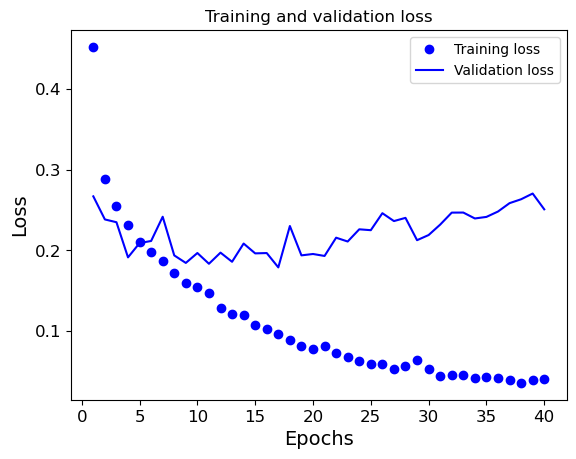

In [18]:
%matplotlib inline
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

# "bo" is for "blue dot"
plt.plot(epochs, loss, 'bo', label='Training loss')
# b is for "solid blue line"
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

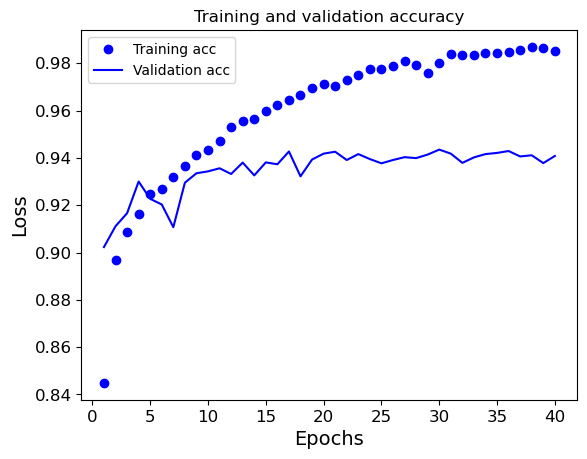

In [19]:
plt.clf()   # clear figure
acc_values = history.history['accuracy']
val_acc_values = history.history['val_accuracy']

plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [20]:
model = build_model()
model.compile(optimizer='nadam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])
history = model.fit([X_train, X_train], y_train, epochs=40, batch_size=64)

Epoch 1/40
938/938 ━━━━━━━━━━━━━━━━━━━━ 86s 84ms/step - accuracy: 0.8549 - loss: 0.4189
Epoch 2/40
938/938 ━━━━━━━━━━━━━━━━━━━━ 78s 84ms/step - accuracy: 0.8998 - loss: 0.2771
Epoch 3/40
938/938 ━━━━━━━━━━━━━━━━━━━━ 73s 78ms/step - accuracy: 0.9117 - loss: 0.2440
Epoch 4/40
938/938 ━━━━━━━━━━━━━━━━━━━━ 78s 83ms/step - accuracy: 0.9195 - loss: 0.2244
Epoch 5/40
938/938 ━━━━━━━━━━━━━━━━━━━━ 71s 76ms/step - accuracy: 0.9245 - loss: 0.2096
Epoch 6/40
938/938 ━━━━━━━━━━━━━━━━━━━━ 73s 78ms/step - accuracy: 0.9306 - loss: 0.1920
Epoch 7/40
938/938 ━━━━━━━━━━━━━━━━━━━━ 71s 75ms/step - accuracy: 0.9341 - loss: 0.1809
Epoch 8/40
938/938 ━━━━━━━━━━━━━━━━━━━━ 85s 91ms/step - accuracy: 0.9364 - loss: 0.1772
Epoch 9/40
938/938 ━━━━━━━━━━━━━━━━━━━━ 71s 75ms/step - accuracy: 0.9414 - loss: 0.1618
Epoch 10/40
938/938 ━━━━━━━━━━━━━━━━━━━━ 70s 75ms/step - accuracy: 0.9457 - loss: 0.1475
Epoch 11/40
938/938 ━━━━━━━━━━━━━━━━━━━━ 73s 78ms/step - accuracy: 0.9495 - loss: 0.1376
Epoch 12/40
938/938 ━━━━━━━━━━

In [21]:
acc = model.evaluate([X_test, X_test], y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9422 - loss: 0.2747


In [22]:
grade = max(0, min((acc[1] - 0.93)/(0.94 - 0.93), 1))*100
print('My grade:', grade)

My grade: 100
